#### Inverse kinematics of `ROBOTIS FFW SG2`
- `sg2`: `s`werve drive with `g`ripper `2`fingers

In [1]:
from package.init_scripts.init_ipython_setup import *
from package.init_scripts.init_qt import *
from package.mujoco_sim import *
from package.kinematics import *
from package.utility import *
from package.qt import *
from PyQt5.QtWidgets import QApplication
app = QApplication(sys.argv)

[qt] package initialized.
Basic packages initialized.
 import numpy as np
 import matplotlib.pyplot as plt
 import scipy as sp
 from PIL import Image
[ipython] settings (retina, inline, qt) initialized.
[numpy] settings initialized.
[matplotlib] settings initialized.


In [2]:
xml_path = merge_mjcfs(
    included_mjcf_files=[
        "../asset/floor/floor_simple_white.xml",
        "../asset/robotis/robotis_ffw/ffw_sg2_site_added.xml",
    ],
    output_xml_path = "xml/scene_ffw_sg2.xml",
)
env = MuJoCoParser(rel_xml_path=xml_path,verbose=False)

[merge_mjcfs] Merging [2] MJCF files:
  - [0] [../asset/floor/floor_simple_white.xml]
  - [1] [../asset/robotis/robotis_ffw/ffw_sg2_site_added.xml]
[merge_mjcfs] Saved merged XML to:[xml/scene_ffw_sg2.xml]
MuJoCo model loaded from [xml/scene_ffw_sg2.xml].


MuJoCo model loaded from [xml/scene_ffw_sg2.xml].


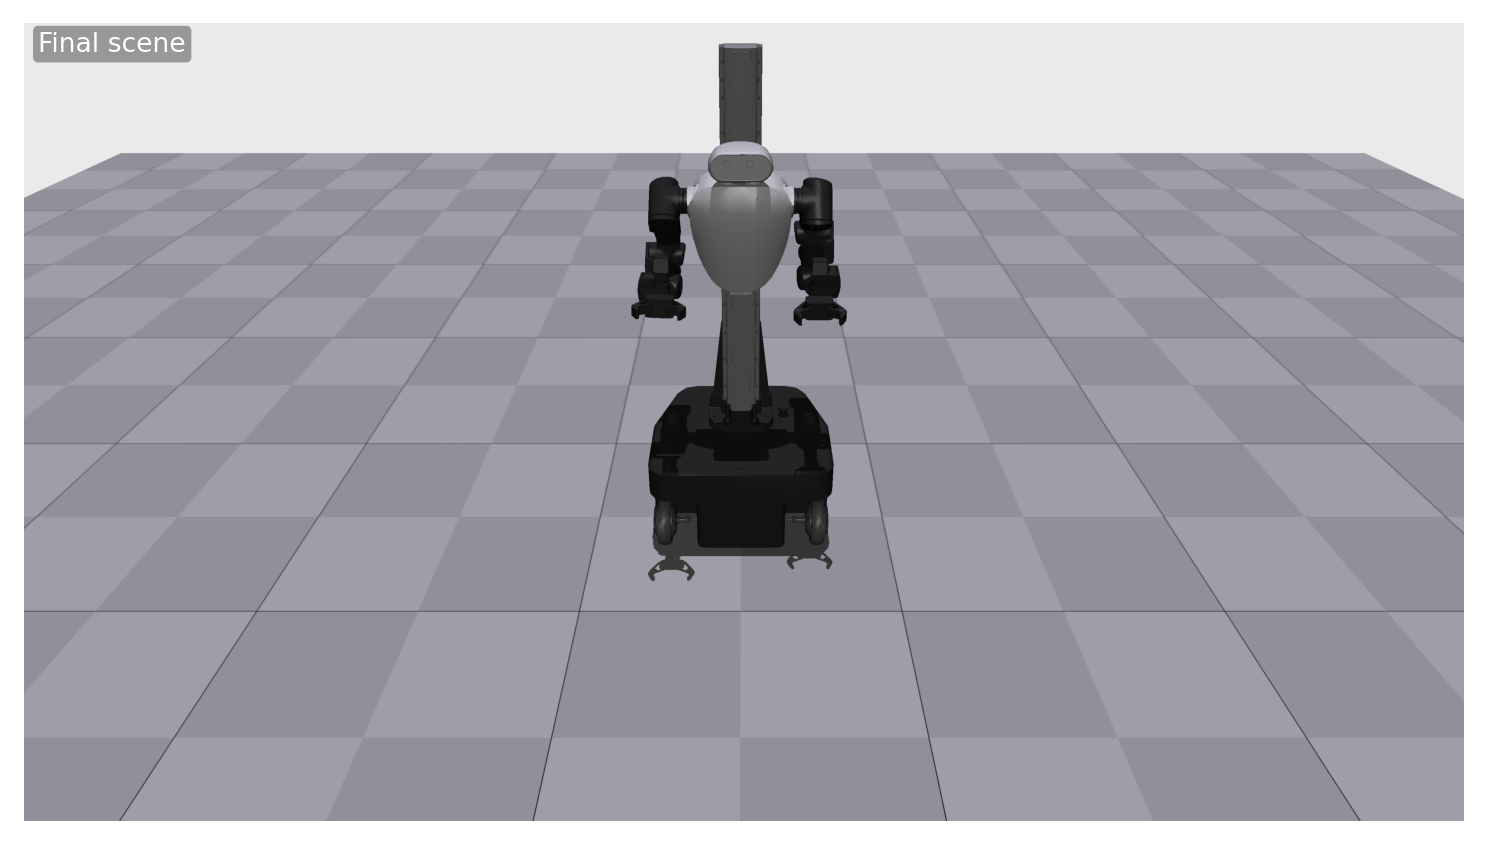

Done.


In [3]:
# Reset
env.reset()
env.init_viewer(title="FFW SG2", width=1.0, height=1.0, fontscale=200)
env.viewer.set_cam_info(180, 3.2, -30, [0.02, 0.01, 0.4])
env.viewer.set_transparency(transparent=False)
env.viewer.set_geomgroup(group_2=True, group_3=False)

def get_R_tcp(env,use_arm='r',use_type="site"):
    p_tcp        = env.get_p(f"gripper_{use_arm}_tcp",type=use_type)
    p_tcp_top    = env.get_p(f"gripper_{use_arm}_tcp_top",type=use_type)
    p_tcp_palmar = env.get_p(f"gripper_{use_arm}_tcp_side",type=use_type)
    p_tcp_front  = env.get_p(f"gripper_{use_arm}_tcp_front",type=use_type)
    ux,uy,uz = np_uv(p_tcp_front-p_tcp),np_uv(p_tcp_palmar-p_tcp),np_uv(p_tcp_top-p_tcp)
    R_tcp   = np.column_stack((ux,uy,uz)).reshape((3,3))
    return R_tcp

# Joint uses
joint_groups = group_by_prefix(items       = env.rev_pri_joint_names,
                               prefix_dict = {'arm_l_joint_names':['arm_l_joint'],
                                              'arm_r_joint_names':['arm_r_joint'],
                                                "lift_joint_name":["lift_joint"],})
use_r_joint_names = joint_groups['arm_r_joint_names']
use_l_joint_names = joint_groups['arm_l_joint_names']
use_lift_joint_name = joint_groups['lift_joint_name']
use_joint_names = use_r_joint_names+use_l_joint_names+use_lift_joint_name

# Init configurations
init_q = [1.07, 0, 0, -2.57, 0, 0, 0]*2+[-0.25]
env.forward(q=init_q, joint_names=use_joint_names)

# IK-related sliders and buttons
p_r_tcp = env.get_p("gripper_r_tcp","site")
R_tcp = get_R_tcp(env)
slider_vals = np.hstack([p_r_tcp,r2rpy(R_tcp)])
sliders = MultiSliderQtWidget(
    title         = "Right Arm",
    y_offset      = 0.05,
    window_width  = 0.2,
    window_height = 0.2,
    label_texts   = ["X","Y","Z","Roll","Pitch","Yaw"],
    slider_mins   = slider_vals-np.array([1,1,1,np.pi,np.pi,np.pi]),
    slider_maxs   = slider_vals+np.array([1,1,1,np.pi,np.pi,np.pi]),
    slider_vals   = slider_vals,
    fontsize      = 30,
)
buttons = MultiRadioQtWidget(
    title         = "IK configurations",
    label_texts   = ["IK_R"],
    option_texts  = [["True","False"]],
    initial_texts = ["True"],
    y_offset      = 0.3,
    window_width  = 0.2,
    window_height = 0.1,
    fontsize      = 30,
)

# Instantiate IK solver
ik_env = MuJoCoParser(rel_xml_path=env.rel_xml_path)
dls_damping = 1e-6 * np.ones(len(use_joint_names)) 
ik_site_solver = SitePositionIKSolverRevPriBase(ik_env           = ik_env,
                                                joints_use       = use_joint_names,
                                                max_ik_tick      = 10,
                                                ik_stepsize_rev  = 10 * D2R,
                                                ik_stepsize_pri  = 0.15,
                                                ik_update_th_rev = 10 * D2R,
                                                ik_update_th_pri = 0.15,
                                                dls_damping      = dls_damping,
                                                max_probe_rev    = 3 * D2R,
                                                max_probe_pri    = 0.01,
                                                k_null           = 0.5,
                                                q_home_rev_pri   = env.get_qpos(joint_names=env.rev_pri_joint_names),)
solve_kwargs = dict(joint_limit_handle_flag     = True,
                    nullspace_control_flag      = True,
                    base_control_flag           = False,)

# Loop
sim_nstep   = 5
tmr_sim     = SimpleTimer(name="Sim",Hz=1.0/(env.dt*sim_nstep),verbose=True)
tmr_render  = SimpleTimer(name="Render",Hz=20,verbose=True)
tmr_sim.start(); tmr_render.start(); env.reset_wall_time(); env.reset_sim_time()

while env.is_viewer_alive():
    app.processEvents()
    if tmr_sim.do_run():
        # Get target positions from sliders
        vals        = sliders.get_values()
        p_tcp_trgt = vals[:3]
        R_tcp_trgt = rpy2r(vals[3:])
        p_tcp_top_trgt    = p_tcp_trgt + 0.1*R_tcp_trgt[:,2]
        p_tcp_palmar_trgt = p_tcp_trgt + 0.1*R_tcp_trgt[:,1]
        p_tcp_front_trgt  = p_tcp_trgt + 0.1*R_tcp_trgt[:,0]

        # Solve IK
        p_r_tcp_curr = env.get_p("gripper_r_tcp","site")
        p_r_tcp_top_curr = env.get_p("gripper_r_tcp_top","site")
        p_r_tcp_palmar_curr = env.get_p("gripper_r_tcp_side","site")
        p_r_tcp_front_curr = env.get_p("gripper_r_tcp_front","site")
        ik_site_solver.reset_buffers()
        ik_site_solver.add_ik_target(site_name="gripper_r_tcp",p_trgt=p_tcp_trgt)
        IK_R = (buttons.get_button_option("IK_R")=="True")
        if IK_R: weight = 1.0
        else: weight = 1e-06 # small weight instead of disabling rotation IK
        ik_site_solver.add_ik_target(site_name="gripper_r_tcp_top",p_trgt=p_tcp_top_trgt,weight=weight)
        ik_site_solver.add_ik_target(site_name="gripper_r_tcp_side",p_trgt=p_tcp_palmar_trgt,weight=weight)
        ik_site_solver.add_ik_target(site_name="gripper_r_tcp_front",p_trgt=p_tcp_front_trgt,weight=weight)
        q_rev_pri_best, ik_info = ik_site_solver.solve_ik(env        = env,
                                                        joints_use = use_joint_names,
                                                        joint_limit_handle_flag = True,
                                                        nullspace_control_flag  = True,
                                                        base_control_flag       = False,)
        ik_err          = ik_info['ik_err_best']
        qpos_used_best  = ik_info["qpos_used_best"]

        # Update
        env.forward(q=qpos_used_best, joint_names=use_joint_names)
        tmr_sim.end()
    
    # Render
    if tmr_render.do_run():
        env.plot_time()
        env.plot_global_coordinate_axes()
        ik_site_solver.render(env,r=0.01,scale_radius_by_weight=True)
        env.viewer_text_overlay("IK error", f"[{ik_err:.6f}]")
        env.plot_contact_info(rate=0.5)
        env.render()
        tmr_render.end()

# Plot final scene
imshow(env.final_rgb_img,fig_w=6,title="Final scene",title_fs=8)

# Close
env.close_viewer()
sliders.close()
buttons.close()
print("Done.")
